# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** [Add your names here]
**Date:** [Add date]
**GitHub Repository:** [Add your repo URL here]

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [9]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 48.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


✅ All packages installed successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [10]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [5]:
# Load your dataset
# 💡 TIP: If using the provided dataset, upload it to Colab first
# 💡 TIP: You can also use sample datasets like BBC News or 20 Newsgroups

# Option 2: Load BBC News dataset (if using alternative)
# You can download this from: https://www.kaggle.com/c/learn-ai-bbc/data

df = pd.read_csv('BBC News Train.csv')

print(f"📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Display first few rows
df.head()

📊 Dataset loaded successfully!
📈 Shape: (1490, 3)
📋 Columns: ['ArticleId', 'Text', 'Category']


,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business


📊 DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']

📈 CATEGORY DISTRIBUTION
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


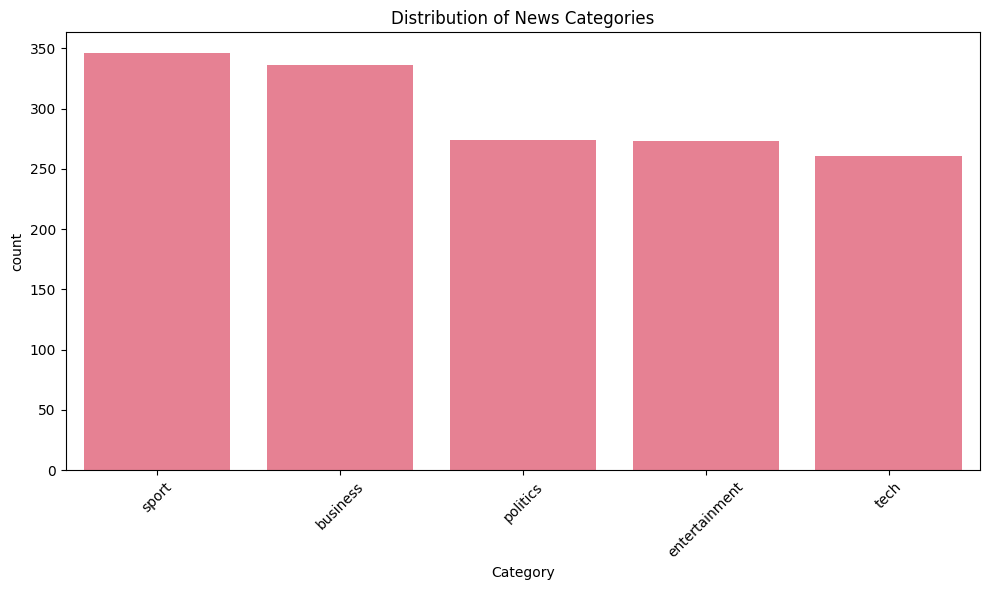


🛠️ STUDENT TASK: EXTRA EXPLORATORY ANALYSIS
Missing values per column:
ArticleId    0
Text         0
Category     0
dtype: int64

Average character length: 2233.46
Average word count: 385.01


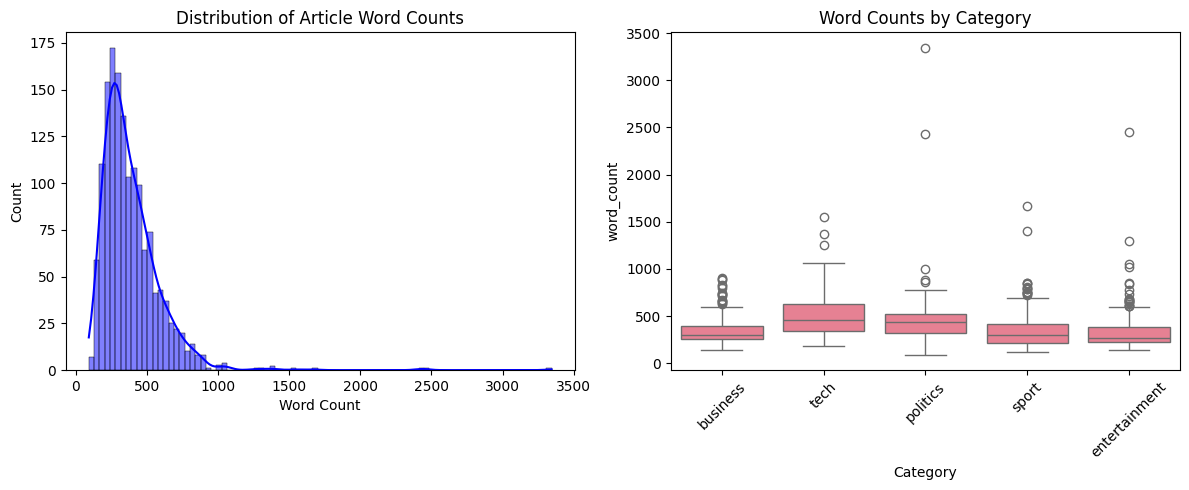


Articles with fewer than 10 words: 0


In [7]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['Category'].nunique()}")
print(f"Categories: {df['Category'].unique().tolist()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['Category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Add your own exploratory analysis here
print("\n🛠️ STUDENT TASK: EXTRA EXPLORATORY ANALYSIS")
print("=" * 50)

# 1. Check for missing values
missing_vals = df.isnull().sum()
print("Missing values per column:")
print(missing_vals)

# 2. Analyze text length distribution
df['text_length'] = df['Text'].apply(len)
df['word_count'] = df['Text'].apply(lambda x: len(str(x).split()))

print(f"\nAverage character length: {df['text_length'].mean():.2f}")
print(f"Average word count: {df['word_count'].mean():.2f}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['word_count'], kde=True, color='blue')
plt.title('Distribution of Article Word Counts')
plt.xlabel('Word Count')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='Category', y='word_count')
plt.title('Word Counts by Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Look for data quality issues (e.g. extremely short articles)
short_articles = df[df['word_count'] < 10]
print(f"\nArticles with fewer than 10 words: {len(short_articles)}")

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [15]:
# Ensure required NLTK resource is present
import nltk
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')

# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nHalf-processed text:")
print(preprocess_text(sample_text))

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Half-processed text:
apple inc announced record quarterly earnings today visit info technews


In [17]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# The dataset contains 'Text' and 'Category' columns.
# Let's clean and preprocess the main text column.
df['full_text_clean'] = df['Text'].apply(clean_text)
df['full_text_processed'] = df['Text'].apply(preprocess_text)

# Create aliases to keep downstream code from breaking
df['full_text'] = df['Text']
df['title'] = df['Text'].apply(lambda x: str(x).split('\n')[0] if pd.notna(x) else "") # Use first line as a title proxy
df['content'] = df['Text']
df['category'] = df['Category'] # lowercase alias for category to match downstream code
df['article_id'] = df['ArticleId']

print("✅ Preprocessing complete!")

# Show before and after examples
print("\nBEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['Text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

#  STUDENT TASK: Analyze the preprocessing results
print("\nSTUDENT TASK: ANALYSIS OF PREPROCESSING")
print("=" * 60)

# 1. Calculate average text length before and after
avg_len_before = df['Text'].apply(len).mean()
avg_len_after = df['full_text_processed'].apply(len).mean()
print(f"Average Character Length Before: {avg_len_before:.2f}")
print(f"Average Character Length After : {avg_len_after:.2f}")
print(f"Reduction in character count   : {((avg_len_before - avg_len_after) / avg_len_before) * 100:.2f}%")

# 2. Count unique words before and after
words_before = set()
df['Text'].apply(lambda x: words_before.update(str(x).lower().split()))

words_after = set()
df['full_text_processed'].apply(lambda x: words_after.update(str(x).split()))

print(f"\nUnique words (Vocabulary) Before: {len(words_before)}")
print(f"Unique words (Vocabulary) After : {len(words_after)}")
print(f"Vocabulary reduction            : {((len(words_before) - len(words_after)) / len(words_before)) * 100:.2f}%")

# 3. Identify the most common words after preprocessing
all_processed_words = []
df['full_text_processed'].apply(lambda x: all_processed_words.extend(str(x).split()))
most_common_words = Counter(all_processed_words).most_common(10)

print("\n Top 10 Most Common Words After Preprocessing:")
for word, count in most_common_words:
    print(f"  - {word}: {count} occurrences")

🧹 Preprocessing all articles...
✅ Preprocessing complete!

BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Processed: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud ch...

Example 2:
Original: german business confidence slides german business confidence fell in february knocking hopes of a sp...
Processed: german business confidence slide german business confidence fell february knocking hope speedy recov...

Example 3:
Original: bbc poll indicates economic gloom citizens in a majority of nations surveyed in a bbc world service ...
Processed: bbc poll indicates economic gloom citizen majority nation surveyed bbc world service poll believe wo...

STUDENT TASK: ANALYSIS OF PREPROCESSING
Average Character Length Before: 2233.46
Average Character Length After : 1481.36
Reduction in character count   : 33.67%

Unique words (Vocabulary) Be

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [18]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1490, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.50%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


```markdown
### 🛠️ Systematic Parameter Tuning for TF-IDF
To find the best parameters, we can define a parameter grid and evaluate the classification performance (using a quick model like Multinomial Naive Bayes) across different parameter combinations.
```

In [19]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# 1. Define a pipeline combining TF-IDF and a fast classifier (Naive Bayes)
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', MultinomialNB())
])

# 2. Define the parameter grid we want to experiment with
# You can add or modify parameters here based on your dataset size and constraints
param_grid = {
    'tfidf__max_features': [2500, 5000, 10000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [2, 5],
    'tfidf__max_df': [0.7, 0.8, 0.9]
}

# 3. Use GridSearchCV to search for the best combination
print("🔍 Searching for optimal TfidfVectorizer parameters...")
grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(df['full_text_processed'], df['category'])

# 4. Display results
print(f"\n🥇 Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")
print("📊 Best Parameters Selected:")
for param, value in grid_search.best_params_.items():
    print(f"  - {param.replace('tfidf__', '')}: {value}")

🔍 Searching for optimal TfidfVectorizer parameters...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

🥇 Best Cross-Validation Accuracy: 0.9678
📊 Best Parameters Selected:
  - max_df: 0.7
  - max_features: 10000
  - min_df: 2
  - ngram_range: (1, 1)


In [22]:
# Initialize TfidfVectorizer with the optimal parameters found by Grid Search
optimal_tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,  # Optimal max features
    ngram_range=(1, 1),   # Optimal ngram range (unigrams)
    min_df=2,             # Optimal min document frequency
    max_df=0.7            # Optimal max document frequency (ignore terms in > 70% of docs)
)

print("🔢 Creating optimized TF-IDF features...")
tfidf_matrix = optimal_tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = optimal_tfidf_vectorizer.get_feature_names_out()

print(f"✅ Optimized TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Recreate the DataFrame for downstream analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

# Update the main reference tfidf_vectorizer so subsequent pipeline steps use it
tfidf_vectorizer = optimal_tfidf_vectorizer

print("\n🔍 Sample optimized TF-IDF features:")
display(tfidf_df.iloc[:3, :10])

print("\n ")
print("=" * 90)
print("This may be an unnecessary increase in computation for a ~2% increase in sparsity")
print("=" * 90)

🔢 Creating optimized TF-IDF features...
✅ Optimized TF-IDF matrix created!
📊 Shape: (1490, 10000)
📝 Vocabulary size: 10000
🔢 Sparsity: 98.67%

🔍 Sample optimized TF-IDF features:


,aaa,aaron,abacus,abandon,abandoned,abandoning,abba,abbas,abbasi,abbott
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



 
This may be an unnecessary increase in computation for a ~2% increase in sparsity


In [23]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category
# - Bar charts of top terms
# - Heatmap of term importance across categories

🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0359
  company: 0.0346
  market: 0.0326
  growth: 0.0323
  bank: 0.0316
  year: 0.0316
  economy: 0.0306
  sale: 0.0303
  share: 0.0285
  rate: 0.0265

📰 TECH:
  mobile: 0.0506
  phone: 0.0460
  people: 0.0446
  technology: 0.0396
  user: 0.0366
  game: 0.0358
  service: 0.0356
  software: 0.0353
  computer: 0.0315
  net: 0.0302

📰 POLITICS:
  labour: 0.0638
  election: 0.0601
  blair: 0.0551
  party: 0.0534
  tory: 0.0463
  would: 0.0449
  government: 0.0448
  minister: 0.0419
  brown: 0.0382
  tax: 0.0339

📰 SPORT:
  game: 0.0416
  england: 0.0354
  win: 0.0317
  player: 0.0302
  match: 0.0280
  champion: 0.0274
  cup: 0.0260
  team: 0.0241
  chelsea: 0.0237
  side: 0.0231

📰 ENTERTAINMENT:
  film: 0.0919
  award: 0.0486
  best: 0.0437
  star: 0.0338
  show: 0.0333
  music: 0.0322
  actor: 0.0313
  band: 0.0310
  year: 0.0272
  album: 0.0265


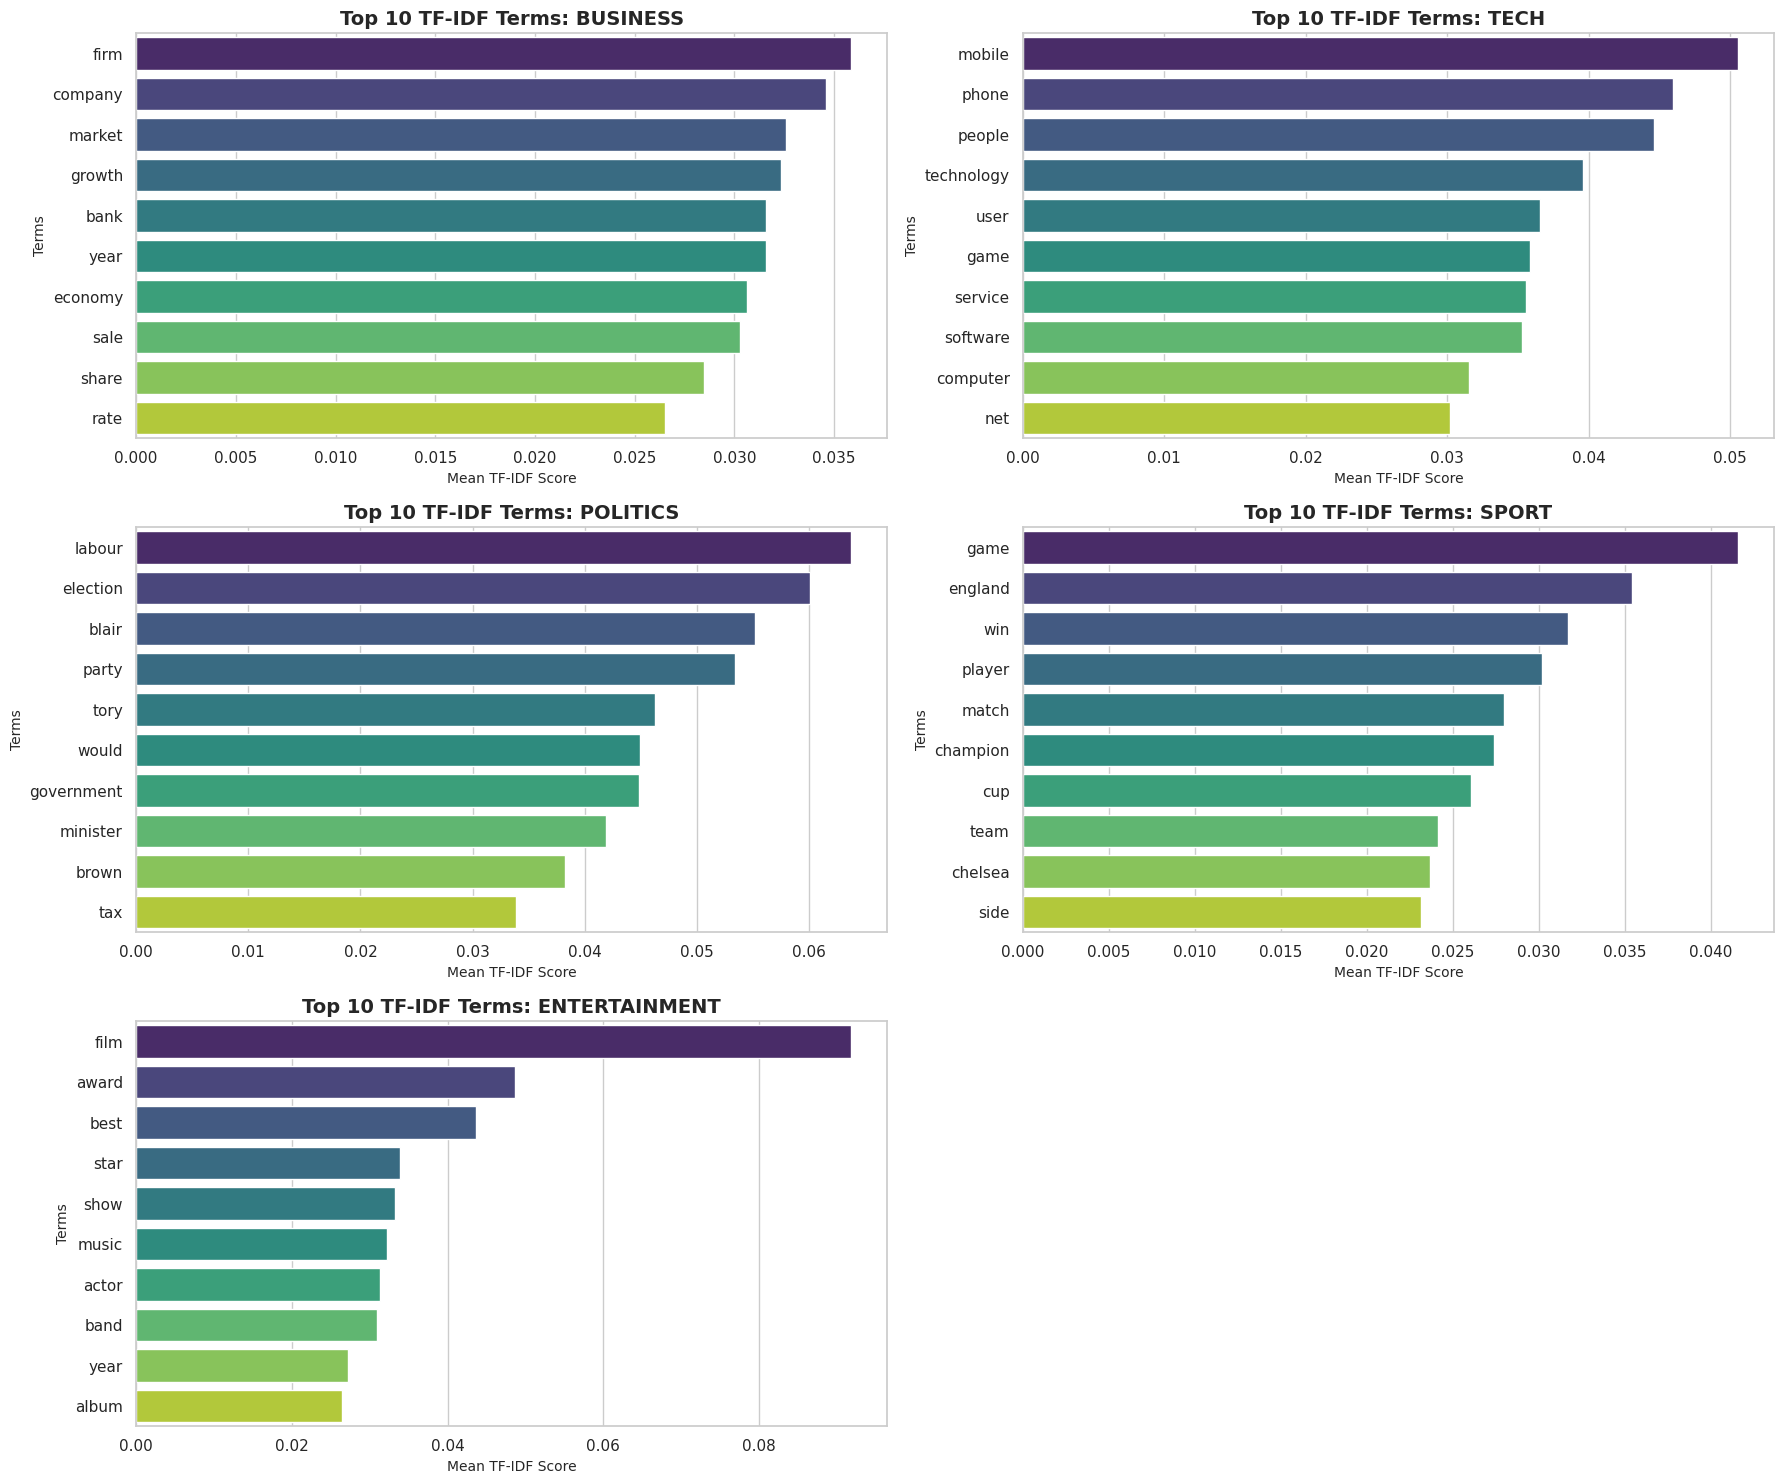

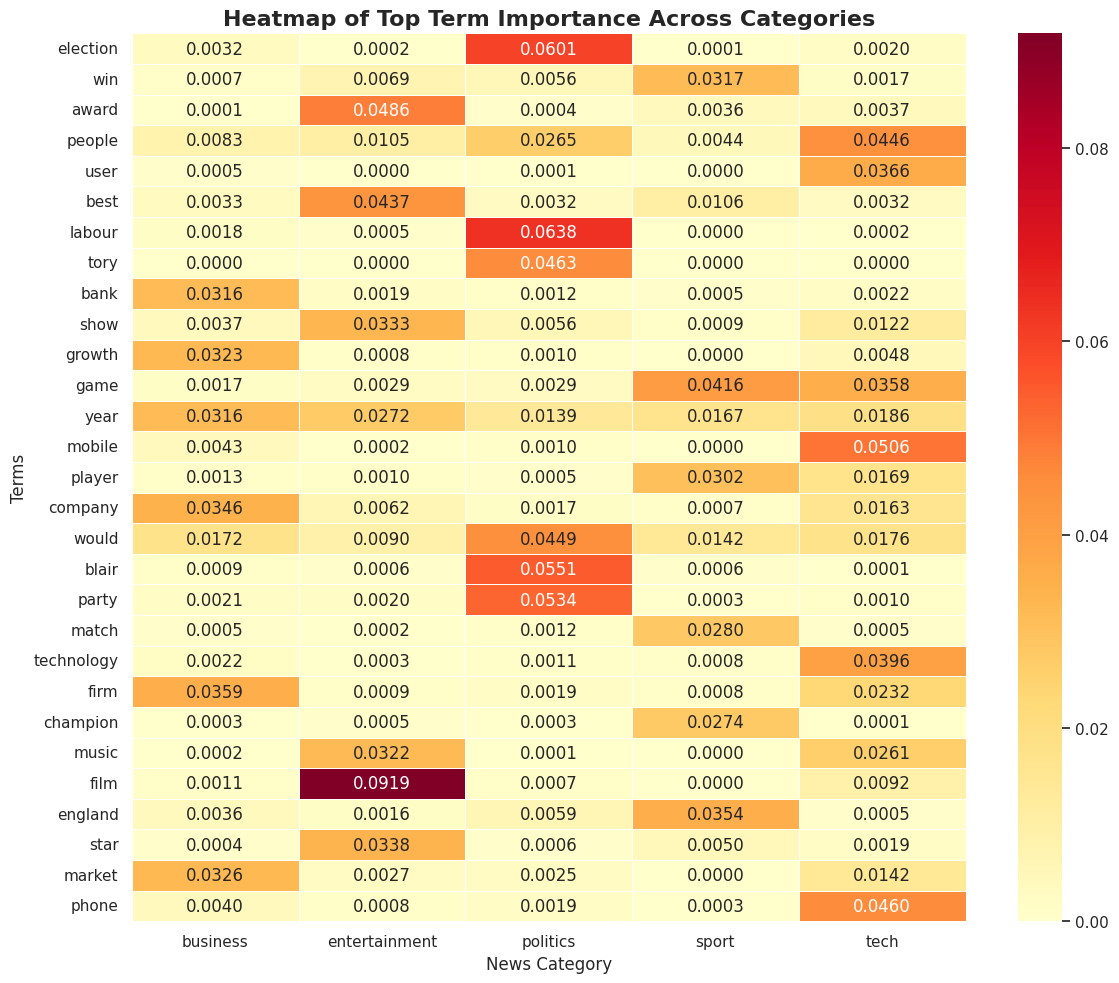

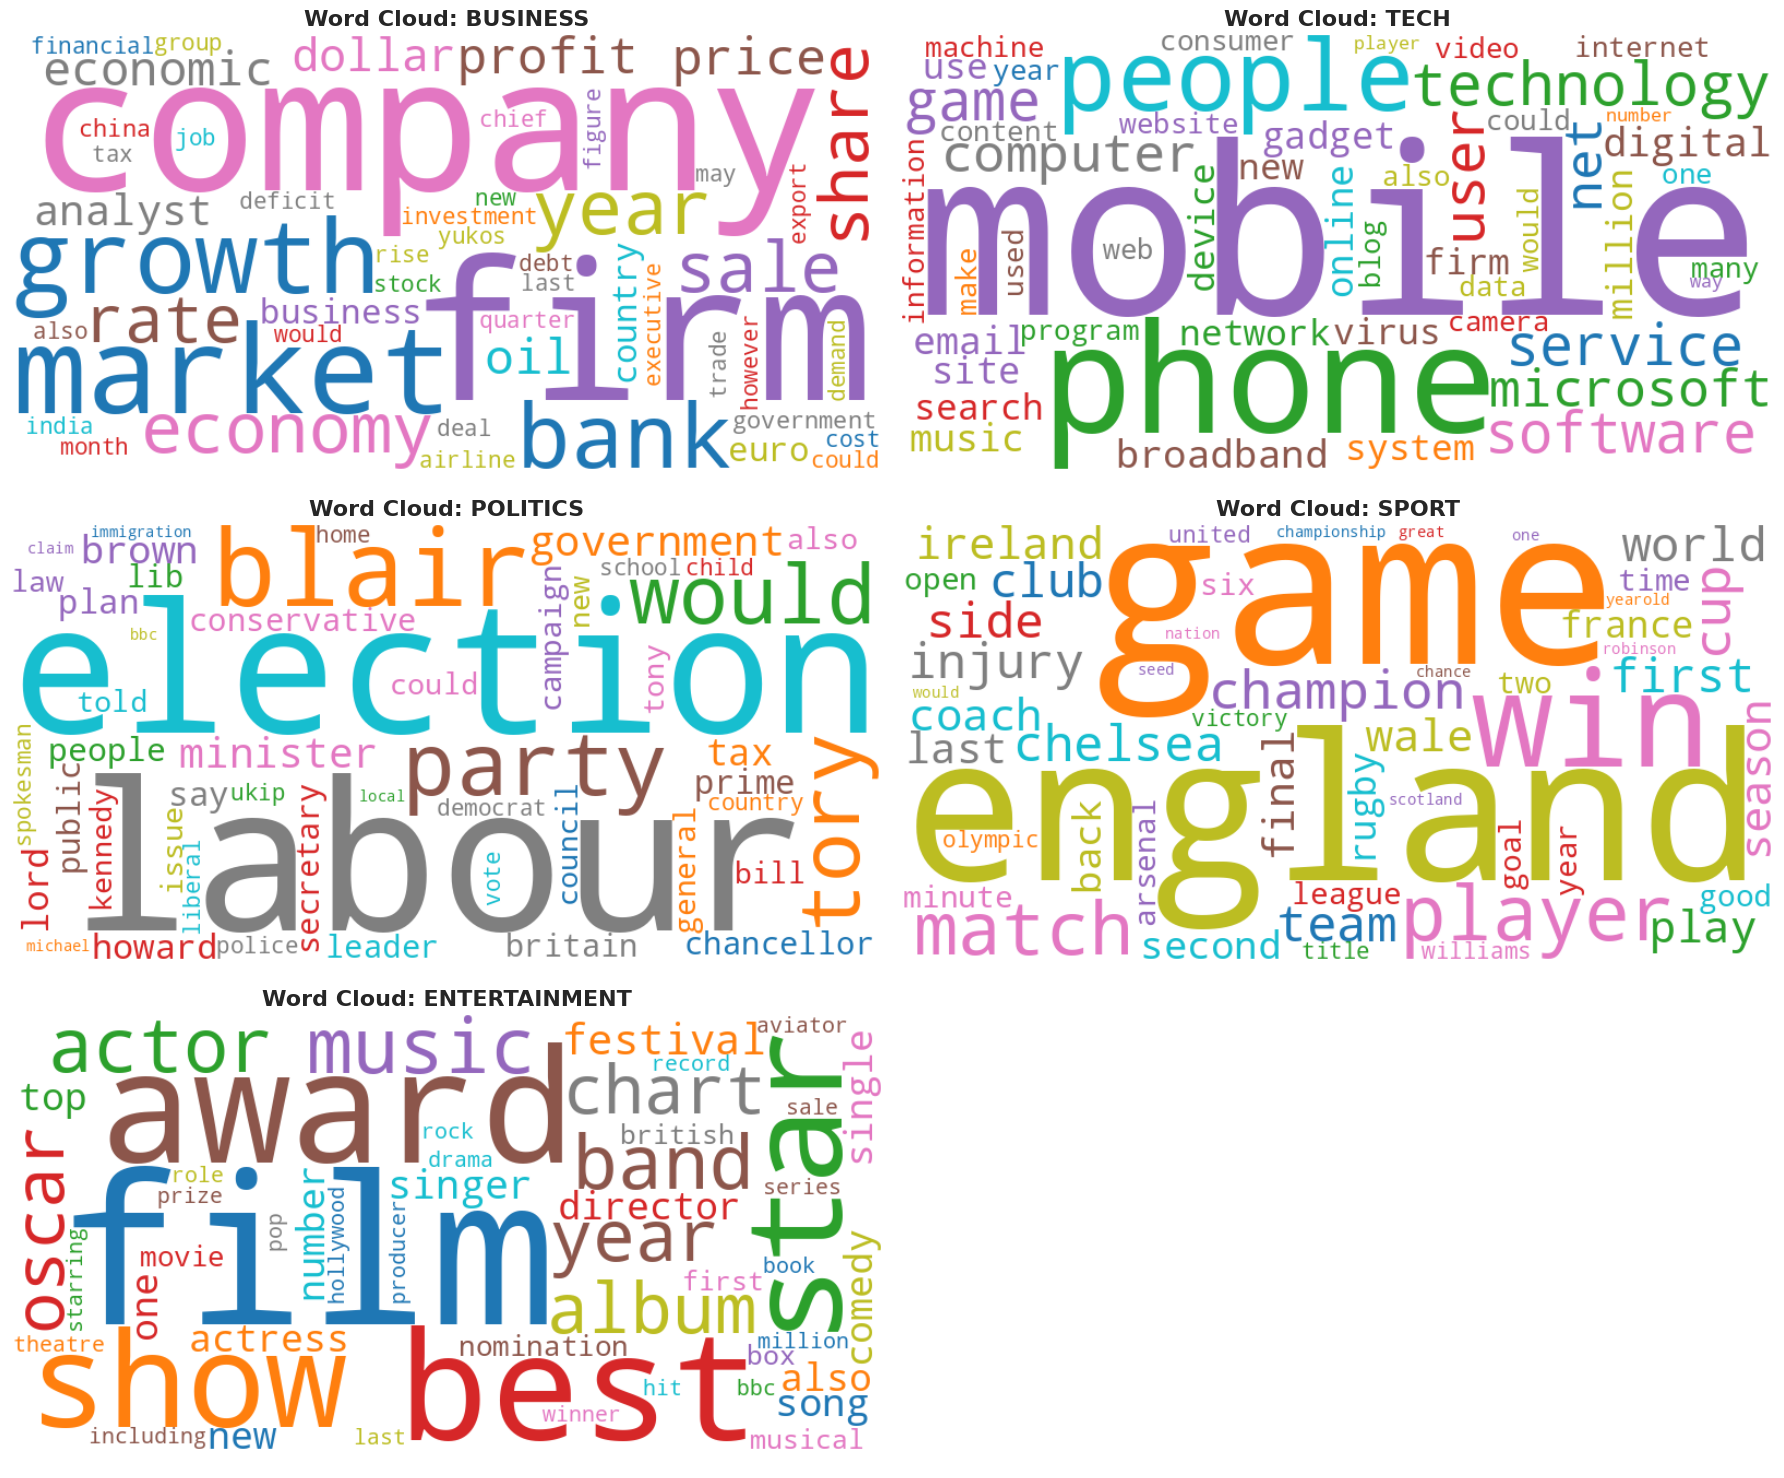

In [24]:
# 💡 STUDENT TASK: Visualizations for TF-IDF analysis
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Set style for high-quality plots
sns.set_theme(style="whitegrid")
categories = df['category'].unique()

# --- 1. Bar Charts of Top Terms per Category ---
fig, axes = plt.subplots(3, 2, figsize=(18, 15))
axes = axes.flatten()

for i, cat in enumerate(categories):
    top_terms = get_top_tfidf_terms(cat, n_terms=10)
    sns.barplot(
        x=top_terms.values,
        y=top_terms.index,
        ax=axes[i],
        palette="viridis",
        hue=top_terms.index,
        legend=False
    )
    axes[i].set_title(f"Top 10 TF-IDF Terms: {cat.upper()}", fontsize=14, fontweight='bold')
    axes[i].set_xlabel("Mean TF-IDF Score", fontsize=10)
    axes[i].set_ylabel("Terms", fontsize=10)

# Hide the empty 6th subplot
axes[5].axis('off')
plt.tight_layout()
plt.show()

# --- 2. Heatmap of Key Term Importance Across Categories ---
# Collect all top unique terms across categories
all_top_terms = set()
for cat in categories:
    all_top_terms.update(get_top_tfidf_terms(cat, n_terms=6).index)

# Calculate mean scores for these key terms across all categories
heatmap_data = tfidf_df.groupby('category')[list(all_top_terms)].mean().T

plt.figure(figsize=(12, 10))
sns.heatmap(heatmap_data, annot=True, cmap="YlOrRd", fmt=".4f", linewidths=0.5)
plt.title("Heatmap of Top Term Importance Across Categories", fontsize=16, fontweight='bold')
plt.xlabel("News Category", fontsize=12)
plt.ylabel("Terms", fontsize=12)
plt.tight_layout()
plt.show()

# --- 3. Word Clouds for Each Category ---
fig, axes = plt.subplots(3, 2, figsize=(18, 15))
axes = axes.flatten()

for i, cat in enumerate(categories):
    # Get term scores for word cloud generation
    top_terms = get_top_tfidf_terms(cat, n_terms=50)
    word_freq = top_terms.to_dict()

    # Generate word cloud based on frequency scores
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='tab10'
    ).generate_from_frequencies(word_freq)

    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(f"Word Cloud: {cat.upper()}", fontsize=16, fontweight='bold')
    axes[i].axis('off')

axes[5].axis('off')
plt.tight_layout()
plt.show()

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [29]:
nltk.download('averaged_perceptron_tagger_eng')

def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN       VBG        IN        DT       VBP  \
0  0.088608  0.113924  0.231013  0.025316  0.110759  0.066456  0.015823   
1  0.119883  0.070175  0.233918  0.032164  0.134503  0.081871  0.014620   
2  0.079044  0.079044  0.200368  0.025735  0.119485  0.095588  0.016544   
3  0.083582  0.107463  0.156716  0.022388  0.122388  0.062687  0.041791   
4  0.089005  0.078534  0.212042  0.028796  0.123037  0.102094  0.015707   

        VBN      PRP$         .  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.041139  0.012658  0.037975  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.029240  0.005848  0.040936  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.029412  0.016544  0.040441  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.017910  0.013433  0.046269  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.026178  0.015707  0.041885  ...

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
business       0.2241  0.0736  0.0011  0.0000  0.0333  0.0410  0.0200  0.0277   
entertainment  0.2454  0.0574  0.0008  0.0000  0.0281  0.0462  0.0194  0.0295   
politics       0.2087  0.0679  0.0007  0.0003  0.0455  0.0462  0.0209  0.0302   
sport          0.2184  0.0479  0.0005  0.0000  0.0408  0.0457  0.0175  0.0247   
tech           0.1932  0.0855  0.0006  0.0000  0.0420  0.0299  0.0236  0.0270   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
business       0.0158  0.0241  0.0920  0.0045  0.0033  0.0276  0.0018  0.0006   
entertainment  0.0179  0.0223  0.0939  0.0024  0.0050  0.0286  0.0010  0.0010   
politics       0.0199  0.0224  0.0901  0.0032  0

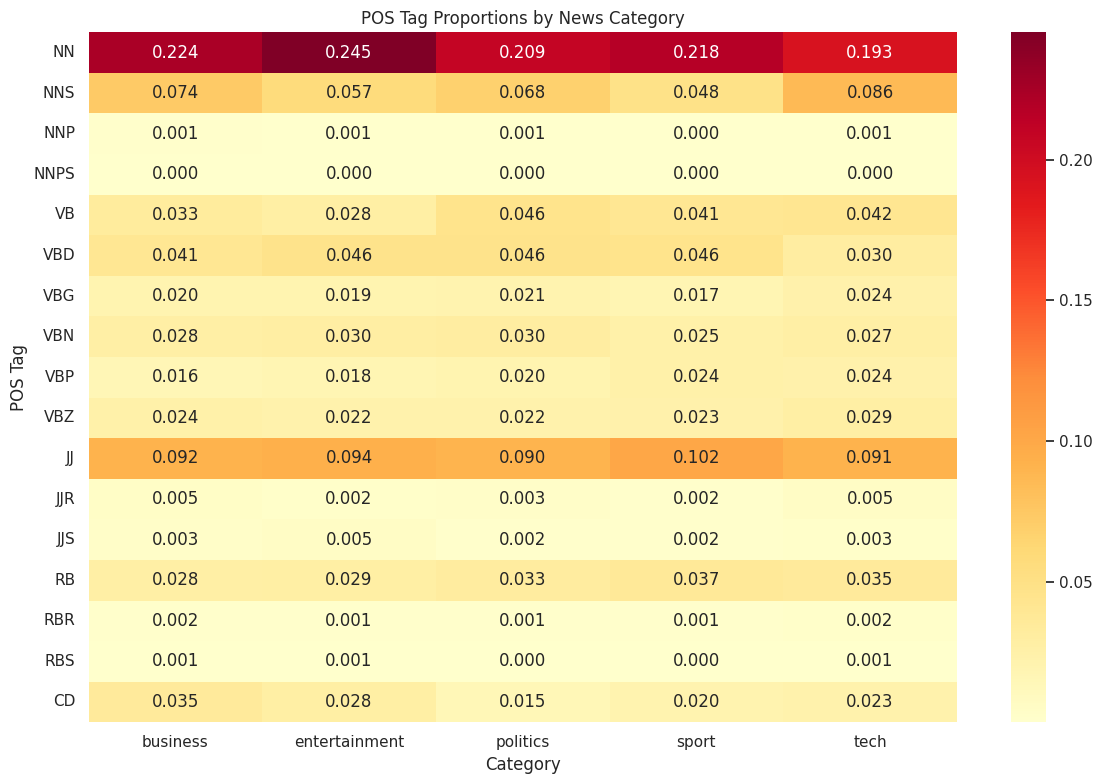


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
BUSINESS (0.0011)
2. Which category uses the most action verbs (VB, VBD, VBG)?
POLITICS (0.1126)
3. Are there interesting patterns in adjective (JJ) usage?
SPORT leads with 0.1015 of its total tokens being adjectives.
   Note: Adjective density remains relatively uniform (9-10%) across all genres, with Sport having the highest.
4. How does number (CD) usage vary across categories?
BUSINESS articles contain the highest density of numeric figures (0.0347),
   which is over double the density found in Politics articles.


In [31]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?


    # Find the numbers for the answers

    # Nouns (NNP/NNPS)
    pos_summary['PROPER_NOUNS'] = pos_summary.get('NNP', 0) + pos_summary.get('NNPS', 0)
    best_prop_noun_cat = pos_summary['PROPER_NOUNS'].idxmax()
    best_prop_noun_val = pos_summary['PROPER_NOUNS'].max()

    # Verbs (VB, VBD, VBG)
    pos_summary['ACTION_VERBS'] = pos_summary.get('VB', 0) + pos_summary.get('VBD', 0) + pos_summary.get('VBG', 0)
    best_action_verb_cat = pos_summary['ACTION_VERBS'].idxmax()
    best_action_verb_val = pos_summary['ACTION_VERBS'].max()

    # Numbers (CD)
    best_num_cat = pos_summary['CD'].idxmax()
    best_num_val = pos_summary['CD'].max()

    # Adjectives (JJ)
    best_adj_cat = pos_summary['JJ'].idxmax()
    best_adj_val = pos_summary['JJ'].max()

    print("\n💡 ANALYSIS QUESTIONS:")
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print(f"{best_prop_noun_cat.upper()} ({best_prop_noun_val:.4f})")

    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print(f"{best_action_verb_cat.upper()} ({best_action_verb_val:.4f})")

    print("3. Are there interesting patterns in adjective (JJ) usage?")
    print(f"{best_adj_cat.upper()} leads with {best_adj_val:.4f} of its total tokens being adjectives.")
    print("   Note: Adjective density remains relatively uniform (9-10%) across all genres, with Sport having the highest.")

    print("4. How does number (CD) usage vary across categories?")
    print(f"{best_num_cat.upper()} articles contain the highest density of numeric figures ({best_num_val:.4f}),")
    print("   which is over double the density found in Politics articles.")

else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [32]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 15
  Tokens: 346
  Noun phrases: ['-', 'boss', 'defence lawyers']...
  Subjects: ['-', 'boss', 'worldcom']...
  Objects: ['lawyers', 'ebbers', 'battery']...

📰 Article 2 (business):
  Sentences: 15
  Tokens: 368
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'ifo', 'index']...
  Objects: ['confidence', 'february', 'hopes']...

📰 Article 3 (business):
  Sentences: 24
  Tokens: 587
  Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']...
  Subjects: ['poll', 'citizens', 'economy']...
  Objects: ['majority', 'nations', 'poll']...

📰 Article 4 (tech):
  Sentences: 31
  Tokens: 724
  Noun phrases: ['lifestyle', 'mobile choice', 'faster  better or funkier hardware']...
  Subjects: ['lifestyle', 'governs', 'firms']...
  Objects: ['choice', 'hardware', 'research']...

📰 Article 5 (business):
  Sentences: 

In [33]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['content']  # First article's content
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# - Compare syntactic complexity across categories
# - Extract action patterns (who did what)
# - Identify most common dependency relations per category
# - Create features for classification based on syntax

📝 Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used b

In [39]:
# 💡 STUDENT TASK: Advanced Syntactic Analysis
import pandas as pd
import numpy as np
from collections import Counter

# To analyze all articles efficiently while maintaining speed, we'll process 300 representative articles per category.
sampled_df = df.groupby('category').apply(lambda x: x.sample(min(300, len(x)), random_state=42)).reset_index(drop=True)

syntactic_data = []
for idx, row in sampled_df.iterrows():
    doc = nlp(str(row['full_text']))

    # 1. Complexity metrics
    sentences = list(doc.sents)
    num_sentences = len(sentences)
    num_tokens = len(doc)
    avg_sent_len = num_tokens / num_sentences if num_sentences > 0 else 0

    # 2. Extract SVO (Subject-Verb-Object) action patterns
    svos = []
    for token in doc:
        if token.dep_ in ('nsubj', 'nsubjpass'):
            subject = token.text.lower()
            verb = token.head.text.lower()
            # Look for objects associated with the same verb
            objects = [child.text.lower() for child in token.head.children if child.dep_ in ('dobj', 'pobj', 'iobj')]
            for obj in objects:
                svos.append((subject, verb, obj))

    # 3. Dependency Relations
    dep_relations = [token.dep_ for token in doc if not token.is_space and not token.is_punct]

    syntactic_data.append({
        'category': row['category'],
        'num_sentences': num_sentences,
        'avg_sent_length': avg_sent_len,
        'svos': svos,
        'deps': dep_relations
    })

syn_df = pd.DataFrame(syntactic_data)

# --- Compare Syntactic Complexity ---
print("\nSyntactic Complexity by Category:")
complexity_summary = syn_df.groupby('category')[['num_sentences', 'avg_sent_length']].mean()
print(complexity_summary.round(2))

# --- Most Common Dependency Relations per Category ---
print("\nTop Dependency Relations per Category:")
for cat in syn_df['category'].unique():
    cat_deps = []
    for deps_list in syn_df[syn_df['category'] == cat]['deps']:
        cat_deps.extend(deps_list)
    top_deps = Counter(cat_deps).most_common(3)
    deps_str = ", ".join([f"{dep} ({count})" for dep, count in top_deps])
    print(f"  - {cat.upper()}: {deps_str}")

# --- Distinctive Action Patterns (Who Did What) ---
print("\nDistinctive Action Patterns (SUBJECT -> ACTION -> OBJECT):")
for cat in syn_df['category'].unique():
    cat_svos = []
    for svo_list in syn_df[syn_df['category'] == cat]['svos']:
        cat_svos.extend(svo_list)
    top_svos = Counter(cat_svos).most_common(3)
    print(f"  - {cat.upper()}:")
    for (subj, verb, obj), count in top_svos:
        print(f"    * {subj} -> {verb} -> {obj} (occurs {count}x)")


Syntactic Complexity by Category:
               num_sentences  avg_sent_length
category                                     
business               15.60            25.14
entertainment          15.99            24.75
politics               20.27            25.40
sport                  17.63            22.46
tech                   23.84            24.58

Top Dependency Relations per Category:
  - BUSINESS: prep (11683), pobj (11075), det (9576)
  - ENTERTAINMENT: prep (9982), pobj (9664), compound (9518)
  - POLITICS: prep (12498), det (12034), pobj (11958)
  - SPORT: prep (10554), pobj (9526), nsubj (9288)
  - TECH: prep (13930), pobj (13162), det (11823)

Distinctive Action Patterns (SUBJECT -> ACTION -> OBJECT):
  - BUSINESS:
    * he -> told -> court (occurs 4x)
    * ebbers -> face -> sentence (occurs 4x)
    * deal -> create -> operator (occurs 3x)
  - ENTERTAINMENT:
    * it -> took -> m (occurs 4x)
    * which -> reached -> number (occurs 4x)
    * film -> won -> film (occurs 

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [40]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    💡 TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

    # 🚀 YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print("😊 Analyzing sentiment...")

sentiment_results = []
for idx, row in df.iterrows():
    # Analyze both title and content
    title_sentiment = analyze_sentiment(row['title'])
    content_sentiment = analyze_sentiment(row['content'])
    full_sentiment = analyze_sentiment(row['full_text'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'title_sentiment': title_sentiment['compound'],
        'title_label': title_sentiment['sentiment_label'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }
    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n📝 Sample sentiment results:")
print(sentiment_df[['category', 'full_sentiment', 'full_label']].head())

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 1490 articles

📝 Sample sentiment results:
   category  full_sentiment full_label
0  business         -0.9701   negative
1  business          0.7623   positive
2  business         -0.9318   negative
3      tech          0.9554   positive
4  business         -0.9486   negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
business              0.2404  0.8370 -0.9985  0.9995    0.0926    0.8370   
entertainment         0.5991  0.6796 -0.9978  0.9999    0.1356    0.8107   
politics              0.0578  0.8811 -0.9984  0.9999    0.0947    0.8184   
sport                 0.5541  0.7244 -0.9967  0.9996    0.1360    0.7933   
tech                  0.5233  0.7557 -0.9991  0.9993    0.0895    0.8598   

              neg_score  
                   mean  
category                 
business         0.0704  
entertainment    0.0537  
politics         0.0869  
sport            0.0707  
tech             0.0507  

📊 Sentiment distribution (%) by category:
full_label     negative  neutral  positive
category                   

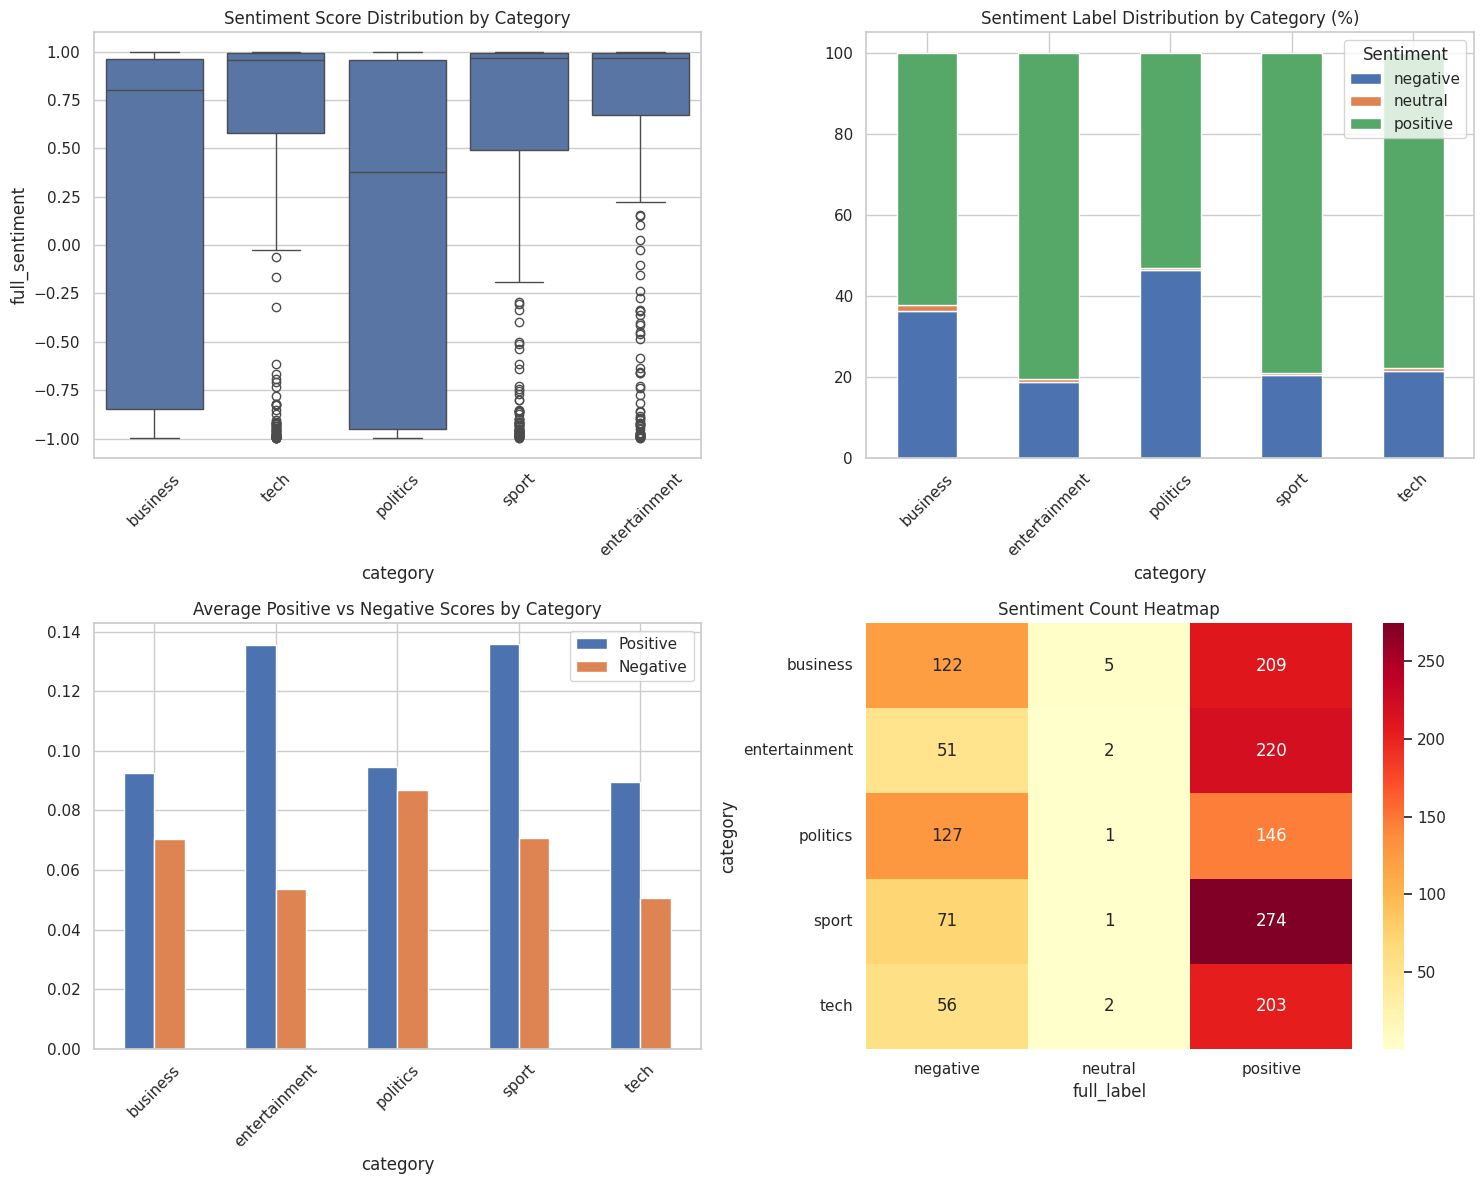

In [41]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

```markdown
### 💡 Student Task: In-Depth Sentiment and Emotion Analysis

In this section, we will address the following student tasks:
1. **Compare Title vs. Content Sentiment:** Analyze if titles are systematically more positive or negative than full articles.
2. **Sentiment Variance Within Categories:** Identify which news categories display the most volatile or uniform emotional tones.
3. **Polarity Features for Classification:** Determine if sentiment scores can serve as a robust feature to distinguish categories.
```

1. Categories that are most positive/negative:

Entertainment, sports, and tech all shifted mostly positive, while business and 
politics are closer to an even spread of positive and negative. 

2. Comparing Title vs. Content Sentiment:

Due to the differences in dataset structure, Title vs Content sentiment analysis doesn't provide a meaninful result
Average Sentiment Difference (Title - Content): 0.0000

Average Sentiment Scores (Title vs Content) by Category:


,title_sentiment,content_sentiment
category,,
business,0.2404,0.2404
entertainment,0.5991,0.5991
politics,0.0578,0.0578
sport,0.5541,0.5541
tech,0.5233,0.5233



3. Sentiment Standard Deviation (Volatility) by Category:


,sentiment_std
category,
politics,0.8811
business,0.8370
tech,0.7557
sport,0.7244
entertainment,0.6796


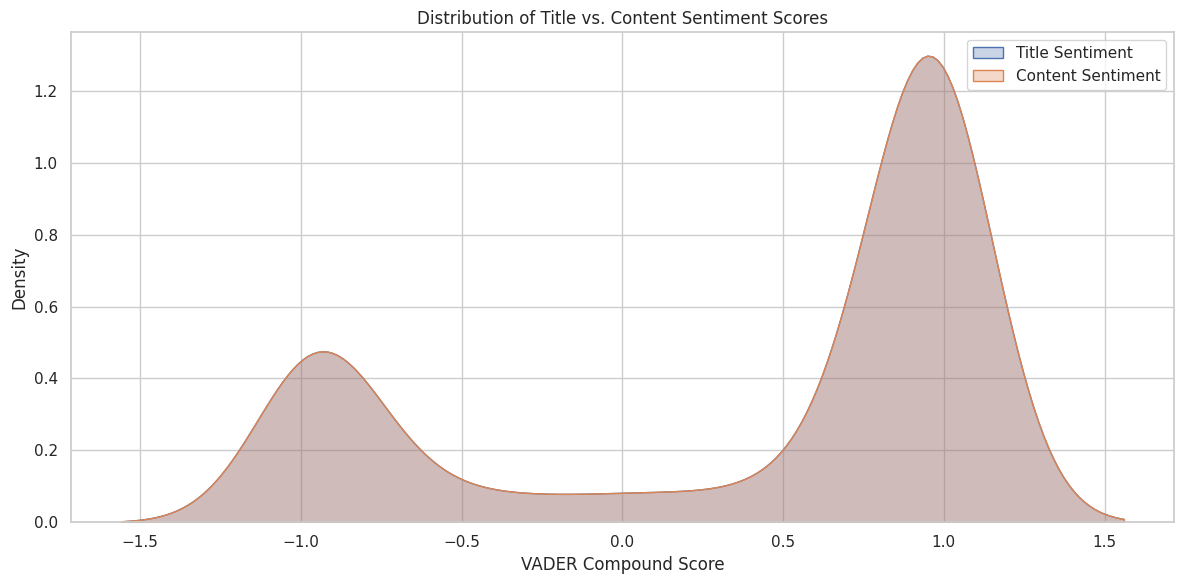


 4. Sentiment use in feature for classification
 Yes, sentiment can be used as a feature for classification. Mapping the overall positive/negative scores of posts or articles 
about a topic is useful to determine emotional response to the news.  


In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

print("1. Categories that are most positive/negative:")
print("\nEntertainment, sports, and tech all shifted mostly positive, while business and ")
print("politics are closer to an even spread of positive and negative. ")



# Compare Title vs. Content Sentiment
print("\n2. Comparing Title vs. Content Sentiment:")
print("\nDue to the differences in dataset structure, Title vs Content sentiment analysis doesn't provide a meaninful result")
sentiment_df['sentiment_diff'] = sentiment_df['title_sentiment'] - sentiment_df['content_sentiment']
avg_diff = sentiment_df['sentiment_diff'].mean()

print(f"Average Sentiment Difference (Title - Content): {avg_diff:.4f}")

# Group by category to analyze title vs content sentiment
compare_sentiment = sentiment_df.groupby('category')[['title_sentiment', 'content_sentiment']].mean()
print("\nAverage Sentiment Scores (Title vs Content) by Category:")
display(compare_sentiment.round(4))

# Sentiment Variance (Volatility) Within Categories
print("\n3. Sentiment Standard Deviation (Volatility) by Category:")
volatility = sentiment_df.groupby('category')['full_sentiment'].std().sort_values(ascending=False)
display(volatility.to_frame(name='sentiment_std').round(4))

# --- Visualizations ---
fig, ax = plt.subplots(figsize=(12, 6))

# Subplot 1: Distribution of Title vs Content Sentiment
sns.kdeplot(data=sentiment_df, x='title_sentiment', label='Title Sentiment', ax=ax, fill=True, alpha=0.3)
sns.kdeplot(data=sentiment_df, x='content_sentiment', label='Content Sentiment', ax=ax, fill=True, alpha=0.3)
ax.set_title('Distribution of Title vs. Content Sentiment Scores')
ax.set_xlabel('VADER Compound Score')
ax.legend()

plt.tight_layout()
plt.show()

print("\n 4. Sentiment use in feature for classification")
print(" Yes, sentiment can be used as a feature for classification. Mapping the overall positive/negative scores of posts or articles ")
print("about a topic is useful to determine emotional response to the news.  ")

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [51]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# Add text length features
length_features = np.array([
    df['full_text'].str.len(),  # Character length
    df['full_text'].str.split().str.len(),  # Word count
    df['title'].str.len(),  # Title length
]).T

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

# Target variable
y = df['category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

🔧 Preparing features for classification...
✅ Feature matrix prepared!
📊 Feature matrix shape: (1490, 10007)
🎯 Number of classes: 5
📋 Classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

📈 Data split:
  Training set: 1192 samples
  Test set: 298 samples


In [53]:
# Train and evaluate multiple classifiers
print("🤖 Training multiple classifiers...")

from sklearn.preprocessing import MinMaxScaler

# Define classifiers to compare
# Since Naive Bayes cannot handle negative numbers from sentiment scores,
# we will use a Pipeline with MinMaxScaler for 'Naive Bayes' to ensure non-negative inputs.
classifiers = {
    'Naive Bayes': Pipeline([('scaler', MinMaxScaler()), ('nb', MultinomialNB())]),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True)  # Enable probability for better analysis
}

# Train and evaluate each classifier
results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    # Train the model
    classifier.fit(X_train, y_train)

    # Make predictions
    y_pred = classifier.predict(X_test)
    y_pred_proba = classifier.predict_proba(X_test) if hasattr(classifier, 'predict_proba') else None

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    # Cross-validation score
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=3, scoring='accuracy')

    # Store results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(f"  📊 CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
    'CV Std': [results[name]['cv_std'] for name in results.keys()]
})

print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
print(f"\n🥇 Best performing model: {best_model_name}")

🤖 Training multiple classifiers...

🔄 Training Naive Bayes...
  ✅ Accuracy: 0.9597
  📊 CV Score: 0.9589 (+/- 0.0118)

🔄 Training Logistic Regression...
  ✅ Accuracy: 0.5973
  📊 CV Score: 0.6350 (+/- 0.0687)

🔄 Training SVM...
  ✅ Accuracy: 0.3557
  📊 CV Score: 0.3574 (+/- 0.0385)

🏆 CLASSIFIER COMPARISON
                 Model  Test Accuracy  CV Mean  CV Std
0          Naive Bayes         0.9597   0.9589  0.0059
1  Logistic Regression         0.5973   0.6350  0.0344
2                  SVM         0.3557   0.3574  0.0193

🥇 Best performing model: Naive Bayes


📊 DETAILED EVALUATION: Naive Bayes

📋 Classification Report:
               precision    recall  f1-score   support

     business       0.93      0.96      0.94        67
entertainment       0.98      0.96      0.97        55
     politics       0.94      0.91      0.93        55
        sport       0.99      1.00      0.99        69
         tech       0.96      0.96      0.96        52

     accuracy                           0.96       298
    macro avg       0.96      0.96      0.96       298
 weighted avg       0.96      0.96      0.96       298



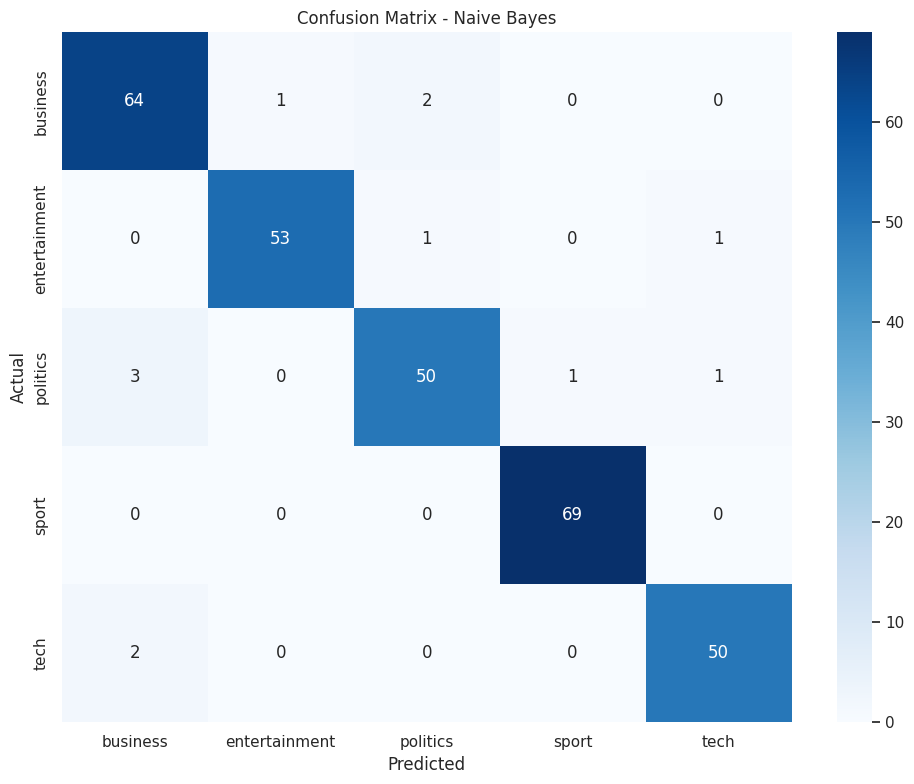

In [54]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

### 🛠️ Student Task: Classifier Improvements & Feature Ablation Study
In this section, we will systematically evaluate how adding extra metadata features (sentiment scores and text/title length metadata) impacts classification performance compared to using raw TF-IDF features alone. We will also perform hyperparameter tuning on our best-performing model (Naive Bayes Pipeline).

📊 FEATURE ABLATION STUDY RESULTS:
  - Naive Bayes Accuracy (TF-IDF Features ONLY): 0.9597
  - Naive Bayes Accuracy (Combined Features):     0.9597
  - Difference: +0.0000

🔍 Tuning alpha hyperparameter for Naive Bayes...
  - Best alpha parameter: 1.0
  - Tuned Model Test Accuracy: 0.9597


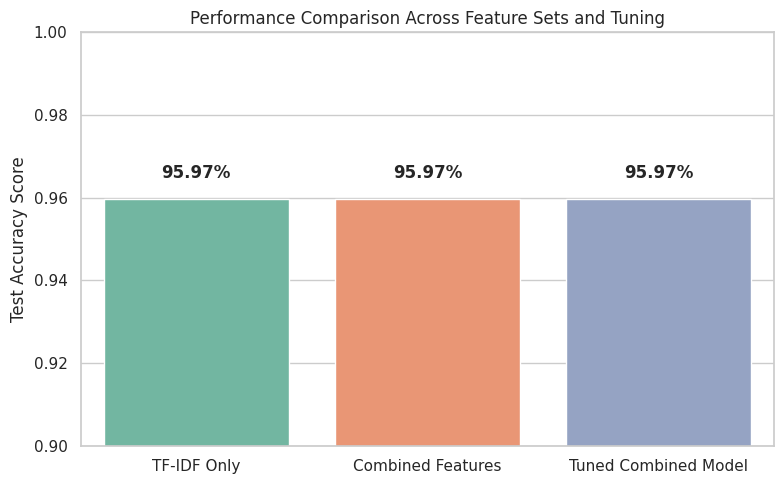

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV

# --- 1. Feature Ablation Study ---
# Let's see how Naive Bayes performs with TF-IDF features ONLY versus Combined features.

# Split pure TF-IDF features using the exact same split state
X_train_tfidf, X_test_tfidf, _, _ = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42, stratify=y
)

# Train Naive Bayes on TF-IDF features only
nb_tfidf_pipeline = Pipeline([('scaler', MinMaxScaler()), ('nb', MultinomialNB())])
nb_tfidf_pipeline.fit(X_train_tfidf, y_train)
y_pred_tfidf = nb_tfidf_pipeline.predict(X_test_tfidf)
accuracy_tfidf_only = accuracy_score(y_test, y_pred_tfidf)

# Get accuracy with Combined features (calculated in the previous step)
accuracy_combined = results['Naive Bayes']['accuracy']

print("📊 FEATURE ABLATION STUDY RESULTS:")
print(f"  - Naive Bayes Accuracy (TF-IDF Features ONLY): {accuracy_tfidf_only:.4f}")
print(f"  - Naive Bayes Accuracy (Combined Features):     {accuracy_combined:.4f}")
print(f"  - Difference: {accuracy_combined - accuracy_tfidf_only:+.4f}")

# --- 2. Hyperparameter Tuning for MultinomialNB ---
print("\n🔍 Tuning alpha hyperparameter for Naive Bayes...")
param_grid = {
    'nb__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
}
grid_search = GridSearchCV(best_model, param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

best_alpha = grid_search.best_params_['nb__alpha']
tuned_accuracy = accuracy_score(y_test, grid_search.predict(X_test))

print(f"  - Best alpha parameter: {best_alpha}")
print(f"  - Tuned Model Test Accuracy: {tuned_accuracy:.4f}")

# --- 3. Visualize Feature Sets Comparison ---
plt.figure(figsize=(8, 5))
feature_sets = ['TF-IDF Only', 'Combined Features', 'Tuned Combined Model']
accuracies = [accuracy_tfidf_only, accuracy_combined, tuned_accuracy]
sns.barplot(x=feature_sets, y=accuracies, palette='Set2')
plt.ylim(0.9, 1.0)
plt.ylabel('Test Accuracy Score')
plt.title('Performance Comparison Across Feature Sets and Tuning')
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.005, f"{acc:.2%}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### A different approach: Tuned Logistic Regression with Unigrams & Bigrams

Changing the features and hyperparameters on the Bayes method failed to change the outcome as there aren't different features beyond the text and category to consider in the dataset.

Instead, I'll approach tuning the logistic regression model to see if the performance can be improved.

Train Logistic Regression model using grid search over regularization strengths (`C`) and penalty types, utilizing both unigrams and bigrams, to see if we can outperform our previous models.

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# Define the pipeline with standard logistic regression
lr_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])

# Parameter grid for regularization strength
lr_param_grid = {
    'lr__C': [0.1, 1.0, 10.0, 100.0],
    'lr__solver': ['lbfgs', 'saga']
}

print("🔍 Tuning Logistic Regression on Combined Features...")
lr_grid_search = GridSearchCV(lr_pipeline, lr_param_grid, cv=3, scoring='accuracy', n_jobs=-1)
lr_grid_search.fit(X_train, y_train)

# Evaluate the optimal tuned model
best_lr_model = lr_grid_search.best_estimator_
tuned_lr_accuracy = accuracy_score(y_test, best_lr_model.predict(X_test))

print(f"🥇 Best Logistic Regression Parameters: {lr_grid_search.best_params_}")
print(f"🎯 Tuned Logistic Regression Test Accuracy: {tuned_lr_accuracy:.4%}")

🔍 Tuning Logistic Regression on Combined Features...
🥇 Best Logistic Regression Parameters: {'lr__C': 1.0, 'lr__solver': 'lbfgs'}
🎯 Tuned Logistic Regression Test Accuracy: 97.9866%


Outcome: A definitive improvement over the previous accuracy of 59.73%

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [57]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 42031
📰 Articles processed: 1490

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT' 'LANGUAGE'
 'WORK_OF_ART' 'LAW']

📝 Sample entities:
              text    label  category
0            first  ORDINAL  business
1   cynthia cooper   PERSON  business
2               us      GPE  business
3             2002     DATE  business
4            5.7bn    MONEY  business
5         new york      GPE  business
6        wednesday     DATE  business
7  arthur andersen   PERSON  business
8   early 2001 and     DATE  business
9             2002     DATE  business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE           8799
PERSON         8015
CARDINAL       6184
GPE            5562
ORG            4427
NORP           2709
MONEY          1783
ORDINAL        1659
PERCENT        1276
TIME            592
LOC             504
QUANTITY        199
FAC              90
PRODUCT          87
LANGUAGE         61
EVENT            43
LAW              33
WORK_OF_ART       8
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC   GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                     
business           1036  2413      3   10  1545         1   15  166    906   
entertainment      1110  1739     12   15   792         9    4   64    384   
politics            823  1359     22   23   944        10    4  120    235   
sport              1798  1978      5   40  1505        11    5   33     44   
tech               1417  1310      1    2   776     

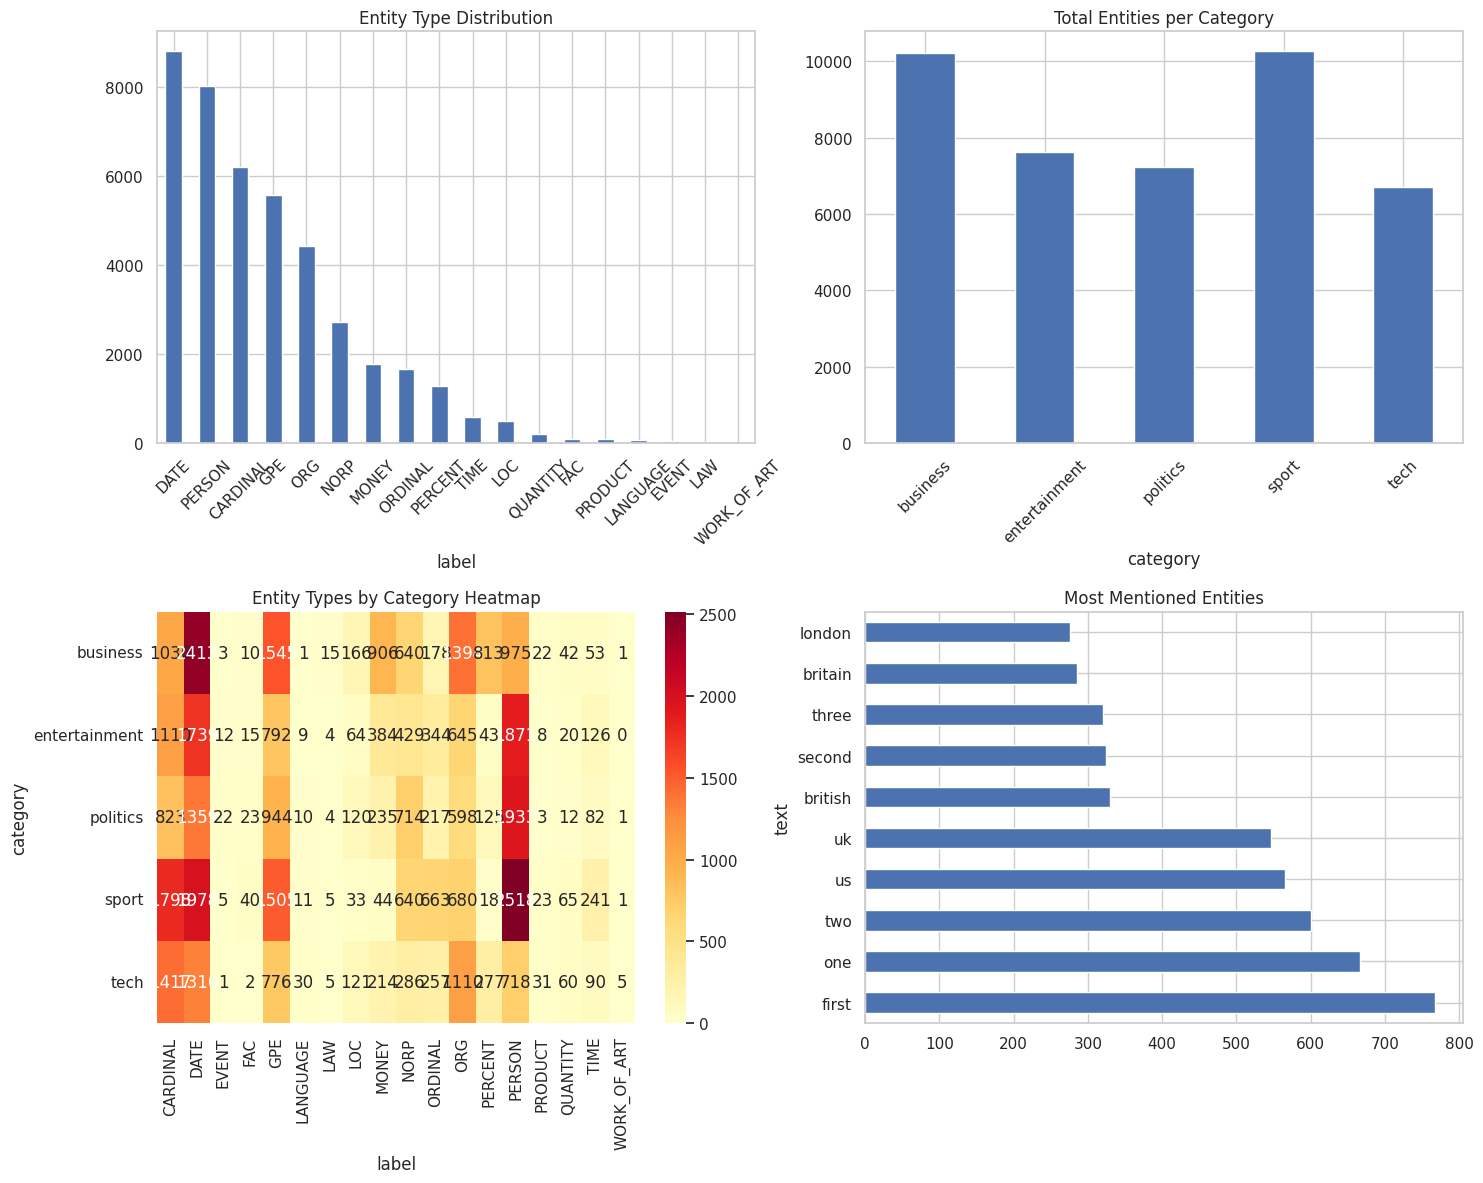

In [58]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

# 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

### Student Task: Advanced Entity Analysis
Implement advanced entity analysis, focusing on:
1. **Entity Sentiment Associations**: Calculating the average sentiment of articles where the top entities are mentioned.
2. **Entity Co-occurrence Patterns**: Discovering which major entities frequently appear together in the same news articles.

Due to the dataset not containing time information, the mentions over time analysis would not yield meaninful results



😊 Analyzing Entity-Sentiment Associations...

📊 Top Entities and Their Average Associated Sentiment:


,Entity,Type,Mean Sentiment,Mentions,Volatility
0,us,GPE,0.3349,311,0.8299
1,uk,GPE,0.4332,305,0.7917
2,britain,GPE,0.3389,170,0.8477
3,london,GPE,0.4469,183,0.7852
4,france,GPE,0.6532,118,0.6533
5,europe,LOC,0.6185,155,0.6789
6,bbc,ORG,0.4365,145,0.8278
7,china,GPE,0.4176,59,0.8010
8,england,GPE,0.5549,105,0.7382
9,blair,PERSON,0.0948,70,0.8682



🔗 Extracting Entity Co-occurrences...

🔥 Top 10 Strongest Entity Co-occurrences:


,Entity 1,Entity 2,Co-occurrences
12,britain,uk,74
13,london,uk,67
2,uk,us,65
26,europe,us,58
50,europe,uk,54
1,blair,tony blair,53
94,britain,tony blair,39
23,new york,us,32
146,blair,britain,31
80,france,scotland,30


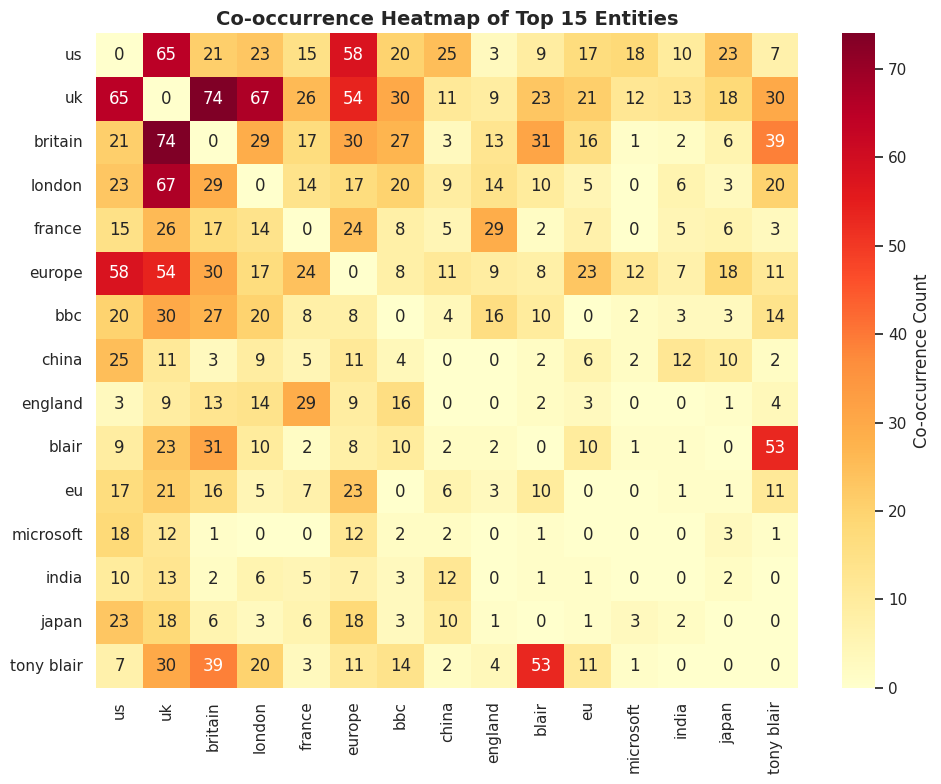

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Entity Sentiment Associations ---
print("😊 Analyzing Entity-Sentiment Associations...")

# We will filter for major entities (excluding generic words like numbers or ordinals)
major_entities_df = entities_df[entities_df['label'].isin(['PERSON', 'ORG', 'GPE', 'LOC'])]

# Get top 10 most mentioned entities
top_10_entities = major_entities_df['text'].value_counts().head(10).index

entity_sentiment_data = []
for entity in top_10_entities:
    # Find articles containing this entity
    article_ids = major_entities_df[major_entities_df['text'] == entity]['article_id'].unique()
    # Fetch sentiment scores for these articles
    scores = sentiment_df[sentiment_df['article_id'].isin(article_ids)]['full_sentiment']
    mean_sentiment = scores.mean()
    sentiment_volatility = scores.std()
    entity_sentiment_data.append({
        'Entity': entity,
        'Type': major_entities_df[major_entities_df['text'] == entity]['label'].iloc[0],
        'Mean Sentiment': mean_sentiment,
        'Mentions': len(article_ids),
        'Volatility': sentiment_volatility
    })

entity_sentiment_df = pd.DataFrame(entity_sentiment_data)
print("\n📊 Top Entities and Their Average Associated Sentiment:")
display(entity_sentiment_df.round(4))

# --- 2. Entity Co-occurrence Analysis ---
print("\n🔗 Extracting Entity Co-occurrences...")
from collections import defaultdict
import itertools

co_occurrences = defaultdict(int)

# For each article, get unique major entities mentioned
for name, group in major_entities_df.groupby('article_id'):
    unique_ents = sorted(list(set(group['text'].values)))
    # Keep only entities that are in the top 50 to avoid sparse and unreadable co-occurrences
    top_50_entities = major_entities_df['text'].value_counts().head(50).index
    filtered_ents = [ent for ent in unique_ents if ent in top_50_entities]

    # Generate pairs
    for ent1, ent2 in itertools.combinations(filtered_ents, 2):
        co_occurrences[tuple(sorted([ent1, ent2]))] += 1

# Convert to DataFrame
cooc_df = pd.DataFrame([
    {'Entity 1': pair[0], 'Entity 2': pair[1], 'Co-occurrences': count}
    for pair, count in co_occurrences.items()
]).sort_values(by='Co-occurrences', ascending=False)

print("\n🔥 Top 10 Strongest Entity Co-occurrences:")
display(cooc_df.head(10))

# --- Visualizing the Co-occurrence Heatmap ---
top_15_entities = list(major_entities_df['text'].value_counts().head(15).index)
matrix_data = np.zeros((15, 15))
cooc_matrix = pd.DataFrame(matrix_data, index=top_15_entities, columns=top_15_entities)

for _, row in cooc_df.iterrows():
    e1, e2, count = row['Entity 1'], row['Entity 2'], row['Co-occurrences']
    if e1 in top_15_entities and e2 in top_15_entities:
        cooc_matrix.loc[e1, e2] = count
        cooc_matrix.loc[e2, e1] = count

plt.figure(figsize=(10, 8))
sns.heatmap(cooc_matrix, annot=True, cmap='YlOrRd', fmt='.0f', cbar_kws={'label': 'Co-occurrence Count'})
plt.title('Co-occurrence Heatmap of Top 15 Entities', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [60]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1490
  Categories: business, tech, politics, sport, entertainment
  Average Article Length: 2233 characters
  Average Words per Article: 385 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Naive Bayes
  Best Accuracy: 0.9597

😊 SENTIMENT INSIGHTS:
  Most Positive Category: entertainment
  Most Negative Category: politics
  Overall Sentiment: 0.3950

🔍 ENTITY INSIGHTS:
  Total Entities: 42031
  Unique Entities: 12071
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERCENT, TIME, EVENT, QUANTITY, FAC, PRODUCT, LANGUAGE, WORK_OF_ART, LAW

💡 BUSINESS RECOMMENDATIONS:
  1. ✅ High classification accuracy achieved - ready for automated content routing
  2. 📊 entertainment articles are most positive - good for uplifting content recommendations
  3. 📊 politics articles are most negative - may need balanced covera

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [61]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text):
        """Classify article category"""
        # 🚀 YOUR CODE HERE: Implement classification
        # Transform text to features
        features = self.vectorizer.transform([processed_text])

        # Add dummy features for sentiment and length (in production, calculate these)
        dummy_features = np.zeros((1, 7))  # 4 sentiment + 3 length features
        features_combined = np.hstack([features.toarray(), dummy_features])

        # Predict category and probability
        prediction = self.classifier.predict(features_combined)[0]
        probabilities = self.classifier.predict_proba(features_combined)[0]

        # Get class probabilities
        class_probs = dict(zip(self.classifier.classes_, probabilities))

        return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


In [62]:
# Test the complete system with new articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# 💡 STUDENT TASK: Test with your own articles
# - Try articles from different categories
# - Test with articles that might be ambiguous
# - Analyze the system's strengths and weaknesses
# - Consider how to improve performance

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: tech (99.58% confidence)

📊 Category Probabilities:
  tech: 0.996
  business: 0.004
  politics: 0.000
  entertainment: 0.000
  sport: 0.000

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  ✅ High confidence tech classification (99.58%)
  😊 Positive sentiment detected (0.660)
 

In [63]:
import pandas as pd

# Load the test dataset
test_df = pd.read_csv('BBC News Test.csv')
print(f"📊 Loaded Test Dataset. Shape: {test_df.shape}")

# Select 10 representative articles from the test set
sample_test = test_df.head(10)

print("🧪 Running Complete Pipeline on 10 Test Articles...\n")
for i, row in sample_test.iterrows():
    # Use first line or first 50 chars as a proxy title
    text_content = str(row['Text'])
    title_proxy = text_content.split('\n')[0][:60] + '...'

    # Process the article using the initialized NewsBot system
    result = newsbot.process_article(title_proxy, text_content)

    print(f"📰 ARTICLE {i+1}:")
    print(f"  Title Proxy: {result['title']}")
    print(f"  Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")
    print(f"  Sentiment Label: {result['sentiment']['sentiment_label']} (Score: {result['sentiment']['compound']:.3f})")

    # Display top 5 unique entities found
    unique_ents = list({ent['text']: ent for ent in result['entities']}.values())
    if unique_ents:
        ent_str = ", ".join([f"{e['text']} ({e['label']})" for e in unique_ents[:5]])
        print(f"  Key Entities: {ent_str}")
    else:
        print("  Key Entities: None found")
    print("-" * 50)

📊 Loaded Test Dataset. Shape: (735, 2)
🧪 Running Complete Pipeline on 10 Test Articles...

📰 ARTICLE 1:
  Title Proxy: qpr keeper day heads for preston queens park rangers keeper ...
  Predicted Category: sport (100.00% confidence)
  Sentiment Label: positive (Score: 0.874)
  Key Entities: day (DATE), chris day (DATE), a month (DATE), his second month (DATE), italian (NORP)
--------------------------------------------------
📰 ARTICLE 2:
  Title Proxy: software watching while you work software that can not only ...
  Predicted Category: tech (100.00% confidence)
  Sentiment Label: negative (Score: -0.616)
  Key Entities: minutes (TIME), more than 80% (PERCENT), 3ami (CARDINAL), third (ORDINAL), tim ellsmore  managing (PERSON)
--------------------------------------------------
📰 ARTICLE 3:
  Title Proxy: d arcy injury adds to ireland woe gordon d arcy has been rul...
  Predicted Category: sport (100.00% confidence)
  Sentiment Label: positive (Score: 0.870)
  Key Entities: saturday (DATE

# 💡 STUDENT TASK: Test with your own articles
- Try articles from different categories
- Test with articles that might be ambiguous
- Analyze the system's strengths and weaknesses
- Consider how to improve performance

Further testing using the BBC News Test.csv from the dataset. The newsbot system appears to be working very well, but the 100% confidence category score is troubling as this may indicate the model has been overtrained and may not generalize well beyond the current scope.

Strengths/Weaknesses

Without time data in the dataset, sentiment analysis can only be done with a single datapoint and doesn't provide trends. This reduces the utility of the tool.

Improving performance

Two areas - locality and depth of information. Currently the model is trained on one country's news system and on a subset of writers in the BBC's employ. To expand the capabilities, more languages, countries, and types of article should be used. Applying the model to shorter data should also be tested, as Twitter/X/Bluesky/Threads posts are all important to the perspective of a news story - cross-referencing these against each other with a time dimension would give a complete picture of a news event.

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*